# 03 — Bridge: from toy environments to a real-ish RPG battle

<div><span style="display:inline-block;background:#334155;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ENVIRONMENT</span><span style="display:inline-block;background:#4C78A8;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">STATE</span><span style="display:inline-block;background:#B279A2;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">TRANSITION</span><span style="display:inline-block;background:#17BECF;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">OBSERVATION</span><span style="display:inline-block;background:#1F3A93;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REPRESENTATION</span><span style="display:inline-block;background:#0F766E;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">POLICY</span><span style="display:inline-block;background:#54A24B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REWARD</span><span style="display:inline-block;background:#ECA82C;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">Q</span></div>

Nothing fundamental changes when we move from LineWorld to Pong to Elder Mist.

What changes is how hard it is to represent the situation and predict consequences.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-030" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Same loop, richer worlds</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LINEWORLD</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-030)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">PONG</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-030)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ATARI</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-030)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ELDER MIST</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-030)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LIFEOS</text>
</svg>
</div>


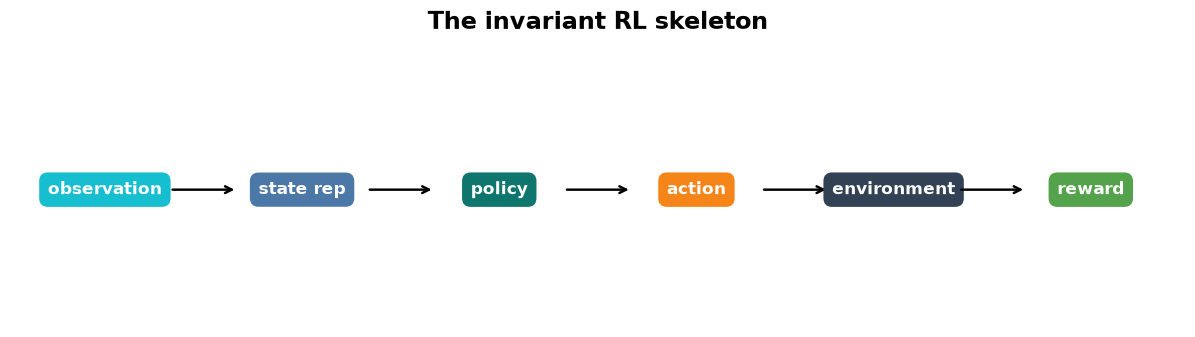

In [1]:
from pathlib import Path
import sys, matplotlib.pyplot as plt
repo = Path.cwd()
if repo.name == "notebooks": repo = repo.parent
sys.path.insert(0, str(repo))
from visuals import pipeline, COLORS

fig = pipeline(
    ["observation","state rep","policy","action","environment","reward"],
    title="The invariant RL skeleton"
)
plt.show()

<div style="border-left:10px solid #4C78A8;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#4C78A8">STATE</div><div style="font-size:21px;font-weight:800;margin-top:4px">Complexity grows in different places</div></div>

LineWorld has trivial observations and transitions.

Elder Mist adds delayed effects, resource management, an active Sword, charged moves, and lock-breaking.

LifeOS adds hidden external facts, messy telemetry, humans, and long horizons.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-032" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Where difficulty comes from</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SIMPLE STATE</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-032)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#B279A2" stroke="#B279A2" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">DELAYED CONSEQUENCES</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-032)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">PARTIAL OBSERVABILITY</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-032)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">REAL WORLD</text>
</svg>
</div>


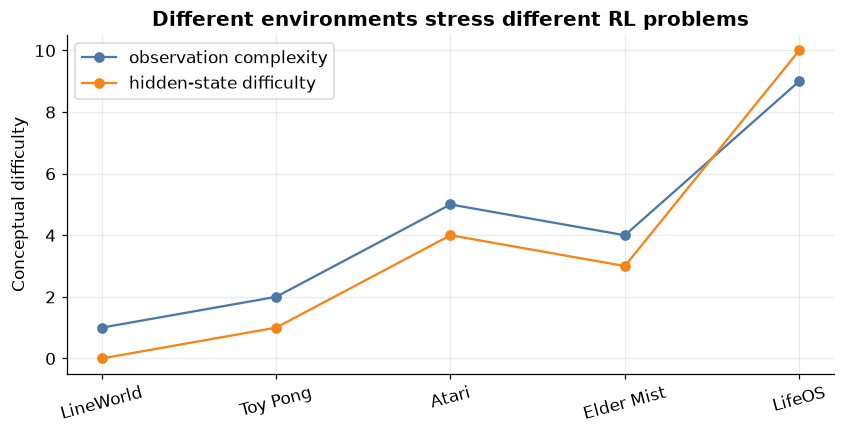

In [2]:
worlds = ["LineWorld","Toy Pong","Atari","Elder Mist","LifeOS"]
obs_complexity = [1,2,5,4,9]
hidden_state = [0,1,4,3,10]

plt.figure(figsize=(9,4))
plt.plot(worlds, obs_complexity, marker="o", label="observation complexity", color=COLORS["STATE"])
plt.plot(worlds, hidden_state, marker="o", label="hidden-state difficulty", color=COLORS["ACTION"])
plt.ylabel("Conceptual difficulty")
plt.title("Different environments stress different RL problems")
plt.legend()
plt.xticks(rotation=15)
plt.show()

<div style="border-left:10px solid #B279A2;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#B279A2">TRANSITION</div><div style="font-size:21px;font-weight:800;margin-top:4px">The key transition</div></div>

For Elder Mist, we control the simulator, so we know the true world state.

That lets us ask a clean experimental question:

> If I hide Sword state from the policy, what breaks?

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-034" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Controlled science</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TRUE STATE KNOWN</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-034)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HIDE A VARIABLE</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-034)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TRAIN SAME POLICY</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-034)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">MEASURE DAMAGE</text>
</svg>
</div>


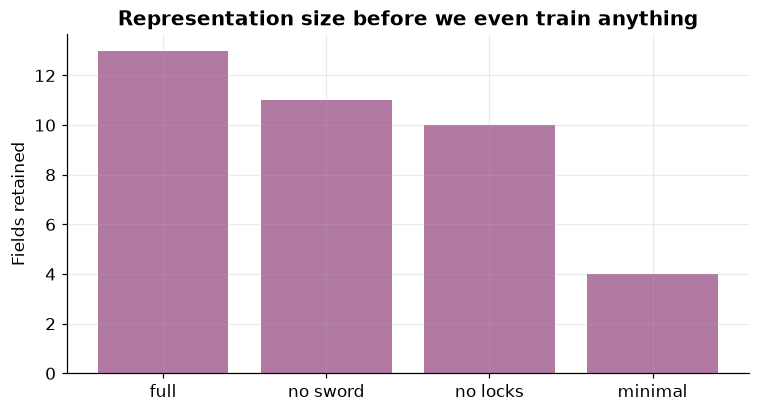

In [3]:
representations = ["full","no sword","no locks","minimal"]
information = [13,11,10,4]

plt.figure(figsize=(8,4))
plt.bar(representations, information, color=COLORS["TRANSITION"])
plt.ylabel("Fields retained")
plt.title("Representation size before we even train anything")
plt.show()

<div style="border-left:10px solid #64748B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#64748B">KEY IDEA</div><div style="font-size:21px;font-weight:800;margin-top:4px">Next notebook</div></div>

Now use the Elder Mist replica as a real Gymnasium-style environment.

You will manually choose actions first, then hand control to rules, Q-learning, and state-representation experiments.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-036" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Elder Mist learning sequence</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">YOU CHOOSE</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-036)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">RULE POLICY</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-036)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#ECA82C" stroke="#ECA82C" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">Q POLICY</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-036)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">REPRESENTATION ABLATION</text>
</svg>
</div>
